# [RQ_3 · HỖ TRỢ] Thí nghiệm cấu hình A — MLP với lịch sử và cờ đóng đường

So **A + lịch sử** với **A + lịch sử + đóng đường**, giữ cùng dữ liệu đã xử lý, bộ tham số MLP và quy tắc lọc giờ đủ lịch sử của V1.

Ảnh thông báo cho biết I-94 ở St. Paul đóng hai chiều giữa Lexington Parkway và I-35E, đồng thời giảm còn một làn mỗi chiều giữa Minnesota Highway 280 và Lexington Parkway. Theo khoảng giờ được chọn cho thí nghiệm, đặt `road_closed=1` từ **09:00 ngày 23/07/2016 đến 04:00 ngày 24/07/2016**, tính cả hai đầu, và **0** ở mọi giờ khác. Đây là khoảng 20 giờ đang xét trong dữ liệu lưu lượng. Ảnh mô tả lịch đóng đường rộng hơn, từ tối thứ Sáu đến chiều Chủ nhật, và không hiển thị ngày cụ thể.

Ba đặc trưng lịch sử vẫn là `lag_24h`, `lag_168h` và `mean_24h`. Các giá trị này dùng lưu lượng thực tế của các giờ đã qua.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## Params

In [1]:
MODEL_PARAMS = {
    "MLP": {
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.001,
        "batch_size": 256,
        "max_iter": 500,
        "early_stopping": False,
        "random_state": 42,
    },
}

CV_SPLITS = 3
CALENDAR_COLUMNS = ["hour", "day_of_week", "month"]
BINARY_COLUMNS = ["is_weekend", "is_holiday"]
TARGET_COLUMN = "traffic_volume"
CLIP_NEGATIVE_PREDICTIONS = True
HOURS_TO_PLOT = 72

ROAD_CLOSED_START = "2016-07-23 09:00"
ROAD_CLOSED_END = "2016-07-24 04:00"

## Đọc dữ liệu, tạo lịch sử và cờ đóng đường

In [2]:
from datetime import datetime
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cwd = Path.cwd()
project_dir = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "metro_interstate_traffic_volume")
        if (candidate / "data" / "processed" / "train.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy data/processed/train.csv.")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.features import HISTORY_FEATURES, add_history_features

processed_dir = project_dir / "data" / "processed"
import sys
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from src.experiment_data import load_experiment_splits

data_splits = load_experiment_splits(project_dir=project_dir)
train, validation = data_splits["train"], data_splits["validation"]

assert train.columns.equals(validation.columns)
for part in (train, validation):
    assert part["date_time"].is_unique
    assert part["date_time"].is_monotonic_increasing
assert train["date_time"].max() < validation["date_time"].min()

holiday_columns = [column for column in train.columns if column.startswith("holiday_")]
binary_columns = BINARY_COLUMNS + holiday_columns
features_A = CALENDAR_COLUMNS + binary_columns

history_table = add_history_features(
    pd.concat([train, validation], ignore_index=True)
)
train = history_table.iloc[:len(train)].copy()
validation = history_table.iloc[len(train):].copy()

for part in (train, validation):
    part["road_closed"] = part["date_time"].between(
        pd.Timestamp(ROAD_CLOSED_START), pd.Timestamp(ROAD_CLOSED_END), inclusive="both",
    ).astype("int8")

CONFIG_FEATURES = {
    "A + lịch sử": [*features_A, *HISTORY_FEATURES],
    "A + lịch sử + đóng đường": [*features_A, *HISTORY_FEATURES, "road_closed"],
}

display(pd.DataFrame([
    {
        "Tập": name,
        "Tổng số giờ": len(part),
        "Số giờ đóng đường": int(part["road_closed"].sum()),
        "Số giờ đủ lịch sử": part[HISTORY_FEATURES].notna().all(axis=1).sum(),
    }
    for name, part in (("Train", train), ("Validation", validation))
]))

,Tập,Tổng số giờ,Số giờ đóng đường,Số giờ đủ lịch sử
0,Train,28402,20,22503
1,Validation,6086,0,6050


## So sánh trên 3 fold theo thời gian

Dùng cùng ranh giới các fold và cùng các giờ đủ lịch sử cho hai mô hình. Cả 20 giờ gắn cờ thuộc phần chấm của fold 3. Các phần học của CV chưa có giờ nào gắn cờ, vì vậy số điểm CV cho biết mô hình phản ứng thế nào với cờ chưa gặp khi học.

In [3]:
def fit_mlp(frame, config):
    columns = CONFIG_FEATURES[config]
    transformers = [
        ("calendar", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CALENDAR_COLUMNS),
        ("binary", "passthrough", binary_columns),
    ]
    transformers.append(("history", StandardScaler(), HISTORY_FEATURES))
    if "road_closed" in columns:
        transformers.append(("closure", "passthrough", ["road_closed"]))

    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer(transformers)),
        ("model", TransformedTargetRegressor(
            regressor=MLPRegressor(**MODEL_PARAMS["MLP"]),
            transformer=StandardScaler(),
        )),
    ])
    return pipeline.fit(frame[columns], frame[TARGET_COLUMN])


def predict_volume(model, frame, config):
    prediction = model.predict(frame[CONFIG_FEATURES[config]])
    if CLIP_NEGATIVE_PREDICTIONS:
        prediction = prediction.clip(min=0)
    return prediction


def keep_history(frame):
    return frame.dropna(subset=HISTORY_FEATURES)


cv_rows = []
for fold, (train_idx, score_idx) in enumerate(TimeSeriesSplit(n_splits=CV_SPLITS).split(train), start=1):
    fit = keep_history(train.iloc[train_idx])
    score = keep_history(train.iloc[score_idx])
    for config in CONFIG_FEATURES:
        print(f"Fold {fold}/{CV_SPLITS} · {config}", flush=True)
        model = fit_mlp(fit, config)
        prediction = predict_volume(model, score, config)
        cv_rows.append({
            "Cấu hình": config,
            "Fold": fold,
            "Giờ train": len(fit),
            "Giờ chấm": len(score),
            "Giờ đóng đường trong train": int(fit["road_closed"].sum()),
            "Giờ đóng đường trong phần chấm": int(score["road_closed"].sum()),
            "MAE giờ đóng đường": (
                mean_absolute_error(score.loc[score["road_closed"].eq(1), TARGET_COLUMN],
                                    prediction[score["road_closed"].eq(1).to_numpy()])
                if score["road_closed"].any() else None
            ),
            "Train đến": fit["date_time"].max(),
            "Chấm từ": score["date_time"].min(),
            "Chấm đến": score["date_time"].max(),
            "MAE": mean_absolute_error(score[TARGET_COLUMN], prediction),
        })

cv_table = pd.DataFrame(cv_rows)
cv_summary = cv_table.groupby("Cấu hình", sort=False)["MAE"].mean().rename("MAE CV").reset_index()
display(cv_table.round(3))
display(cv_summary.round(3))

Fold 1/3 · A + lịch sử
Fold 1/3 · A + lịch sử + đóng đường
Fold 2/3 · A + lịch sử
Fold 2/3 · A + lịch sử + đóng đường
Fold 3/3 · A + lịch sử
Fold 3/3 · A + lịch sử + đóng đường


,Cấu hình,Fold,Giờ train,Giờ chấm,Giờ đóng đường trong train,Giờ đóng đường trong phần chấm,MAE giờ đóng đường,Train đến,Chấm từ,Chấm đến,MAE
0,A + lịch sử,1,5841,5302,0,0,NaN,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,247.266
1,A + lịch sử + đóng đường,1,5841,5302,0,0,NaN,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,247.996
2,A + lịch sử,2,11143,4441,0,0,NaN,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,245.850
3,A + lịch sử + đóng đường,2,11143,4441,0,0,NaN,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,239.386
4,A + lịch sử,3,15584,6919,0,20,1531.568,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,254.676
5,A + lịch sử + đóng đường,3,15584,6919,0,20,1605.621,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,251.014


,Cấu hình,MAE CV
0,A + lịch sử,249.264
1,A + lịch sử + đóng đường,246.132


## Đánh giá trên validation và lưu Excel

Fit lại hai mô hình trên cùng tập train đủ lịch sử. Khi đó tập train chứa 20 giờ gắn cờ. Validation chỉ có cờ bằng 0. Kết quả validation đo ảnh hưởng của việc thêm cờ vào quá trình huấn luyện đối với các giờ không gắn cờ. File Excel ghi điểm, tham số và số giờ gắn cờ trong từng tập.

In [4]:
fit = keep_history(train)
score = keep_history(validation)
prediction_table = score[["date_time", TARGET_COLUMN, "road_closed"]].copy()
rows = []
for config in CONFIG_FEATURES:
    print(f"Validation · {config}", flush=True)
    model = fit_mlp(fit, config)
    prediction = predict_volume(model, score, config)
    prediction_table[config] = prediction
    rows.append({
        "Cấu hình": config,
        "Số đặc trưng": len(CONFIG_FEATURES[config]),
        "Giờ train": len(fit),
        "Giờ validation": len(score),
        "Giờ đóng đường trong train": int(fit["road_closed"].sum()),
        "Giờ đóng đường trong validation": int(score["road_closed"].sum()),
        "Bắt đầu đóng đường": ROAD_CLOSED_START,
        "Kết thúc đóng đường": ROAD_CLOSED_END,
        "MAE": mean_absolute_error(score[TARGET_COLUMN], prediction),
        "RMSE": mean_squared_error(score[TARGET_COLUMN], prediction) ** 0.5,
        "R2": r2_score(score[TARGET_COLUMN], prediction),
        "n_iter": model.named_steps["model"].regressor_.n_iter_,
    })

params = {**MODEL_PARAMS["MLP"], "hidden_layer_sizes": str(MODEL_PARAMS["MLP"]["hidden_layer_sizes"])}
results = pd.DataFrame(rows).merge(cv_summary, on="Cấu hình", validate="one_to_one").assign(**params)
baseline_mae = results.loc[results["Cấu hình"].eq("A + lịch sử"), "MAE"].iloc[0]
results["Chênh MAE so với A + lịch sử"] = results["MAE"] - baseline_mae
display(results.round({"MAE": 3, "RMSE": 3, "R2": 4, "MAE CV": 3}))

run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S_%f")
experiment_dir = project_dir / "experiments" / "18-11-2026_ConfigA_HistoryMLP_Phuc"
excel_path = experiment_dir / f"ConfigA_MLP_History_V2_RoadClosure_{run_id}.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Kết quả", index=False)
    cv_table.to_excel(writer, sheet_name="CV từng fold", index=False)
print(f"Đã lưu Excel tại {excel_path}")

Validation · A + lịch sử
Validation · A + lịch sử + đóng đường


,Cấu hình,Số đặc trưng,Giờ train,Giờ validation,Giờ đóng đường trong train,Giờ đóng đường trong validation,Bắt đầu đóng đường,Kết thúc đóng đường,MAE,RMSE,...,hidden_layer_sizes,activation,solver,alpha,learning_rate_init,batch_size,max_iter,early_stopping,random_state,Chênh MAE so với A + lịch sử
0,A + lịch sử,20,22503,6050,20,0,2016-07-23 09:00,2016-07-24 04:00,194.780,302.769,...,"(64, 32)",relu,adam,0.001,0.001,256,500,False,42,0.000000
1,A + lịch sử + đóng đường,21,22503,6050,20,0,2016-07-23 09:00,2016-07-24 04:00,205.722,314.558,...,"(64, 32)",relu,adam,0.001,0.001,256,500,False,42,10.941904


Đã lưu Excel tại d:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\18-11-2026_ConfigA_HistoryMLP_Phuc\ConfigA_MLP_History_V2_RoadClosure_20261118_093947_117004.xlsx


## Vẽ và lưu biểu đồ dự đoán

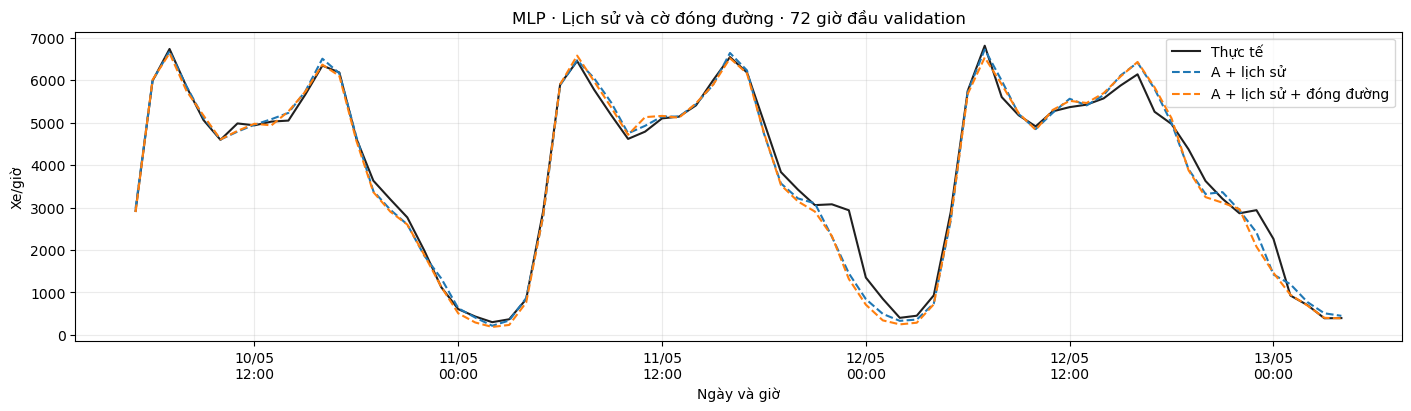

In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plot_index = pd.date_range(
    start=prediction_table["date_time"].min(),
    periods=HOURS_TO_PLOT,
    freq="h",
)
# Giữ NaN ở các giờ thiếu để biểu đồ ngắt tại khoảng trống.
plot_data = prediction_table.set_index("date_time").reindex(plot_index)

fig, ax = plt.subplots(figsize=(14, 4), layout="constrained")
ax.plot(plot_data.index, plot_data[TARGET_COLUMN], color="#202020", label="Thực tế")
for config in CONFIG_FEATURES:
    ax.plot(plot_data.index, plot_data[config], linestyle="--", label=config)
ax.set_title("MLP · Lịch sử và cờ đóng đường · 72 giờ đầu validation")
ax.set_ylabel("Xe/giờ")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.set_xlabel("Ngày và giờ")

output_dir = experiment_dir / "img"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"config_a_mlp_history_v2_road_closure_{HOURS_TO_PLOT}h_{run_id}.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

<!-- proposal-assessment -->
## Đánh giá đối với proposal — RQ_3

**Vai trò: HỖ TRỢ.** Mã đối chiếu: [E28](../../docs/experiment_tracking/EXPERIMENTS_BY_DATE_AND_RQ.md). 

- **Câu hỏi:** Đánh dấu khoảng bất thường đã chọn có giúp mô hình A+lịch sử không?
- **Đánh giá:** Thử sửa mô hình sau khi nhận diện đoạn bất thường bằng cờ đóng đường: MAE 194,780→205,722 và RMSE 302,769→314,558, nên hiện chưa có lý do thêm cờ này vào pipeline chuẩn.
- **Giới hạn kết luận:** Đây là thăm dò hỗ trợ RQ_3, chưa chứng minh nguyên nhân sai số. Khoảng 20 giờ và nguồn sự kiện cần xác minh; validation không có mẫu cờ dương nên chưa đánh giá được chất lượng khi thực sự đóng đường.
- **Bằng chứng:** [E28: ConfigA_MLP_History_V2_RoadClosure_20261118_093947_117004.xlsx](ConfigA_MLP_History_V2_RoadClosure_20261118_093947_117004.xlsx).

Đánh giá trên dựa vào hiện vật lịch sử đã đối chứng, không phải kết quả chạy mới. Code lấy dữ liệu đã được chuẩn hóa; chưa huấn luyện lại hoặc chấm test.
